# 04 – Erweiterung: Empfänger-Modell mit Tracking-Daten

**Frage:** Wie viel besser wird das Zonenmodell (Notebook 02), wenn es aus den Tracking-Daten weiß, wo die Spieler im Moment des Abspiels stehen?

**Idee:** Das Modell beschreibt jeden Pass vom Empfänger aus, als wäre er bekannt: wie weit er weg ist, wie frei er steht und wie viele Gegner im Weg zu ihm stehen. Dazu kommt der Druck auf den Passgeber. Den Empfänger kennen wir bei Fehlpässen nicht (Notebook 01, Abschnitt 5). Er wird deshalb mit einer festen Regel geschätzt, für angekommene und Fehlpässe gleich, ohne den Ausgang zu kennen.

**Merkmale:** die 17 Merkmale des Zonenmodells und 4 aus dem Tracking (Code: `tracking.py`, `empfaenger.py`).

| Merkmal | Definition | Frage dahinter |
|---|---|---|
| `druck_abstand` | Abstand des nächsten Gegners zum Passgeber im Abspielmoment, gekappt bei 15 m | Wie viel Zeit hat der Passgeber? |
| `empf_distanz` | Entfernung zum Empfänger, Position 1 s vorausgerechnet, gekappt bei 70 m | Wie weit ist der Pass? |
| `empf_gegner_abstand` | Abstand des nächsten Gegners zum Empfänger (beide 1 s vorausgerechnet), gekappt bei 20 m | Wie frei steht der Empfänger? |
| `korridor_gegner` | Gegner im Korridor ±15° um die Linie zum Empfänger, zwischen Passgeber und Empfänger, bei 3 gedeckelt | Wie viele Gegner stehen im Weg? |

**Passrichtung:** Statt des DFL-Winkels, der bei abgefälschten Bällen zum Abfangpunkt zeigen könnte (Notebook 01, Abschnitt 6), nimmt das Modell den Ballweg der ersten 0,12 s nach dem Abschlag.

**Ausführen:** Beim ersten Mal liest das Notebook das Roh-Tracking aller 7 Spiele ein (je ca. 400 MB über kloppy, je ca. 1 Minute und ca. 4 GB Arbeitsspeicher). Die Momentaufnahme je Pass wird in `data/momentaufnahme_*.csv` gespeichert und danach von dort gelesen. Zum Neuberechnen die beiden Dateien löschen.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
DATA = ROOT / "data"
from auswertung import ROLLEN, bilanz, mit_rollen
from empfaenger import (EINDEUTIG_AB, leave_one_match_out_mit_rueckfall, logloss_differenz, modell_merkmale,
                        passrichtung, tracking_merkmale)
from modell import leave_one_match_out, neues_modell, pass_auswahl, zonen_merkmale
from passdaten import MATCH_IDS, lade_pass_tabelle
from tracking import momentaufnahmen_spiel

FARBEN = {"Zonenmodell": "#2a78d6", "Empfänger-Modell": "#eb6834"}

## 1. Daten: Momentaufnahme im Abspielmoment

Event-Zeit und Tracking liegen bis zu ca. 2–3 s auseinander. Für jeden Pass sucht `tracking.abspiel_frame` deshalb im Zeitfenster um das Event den Moment, in dem der Ball den Fuß des Passgebers verlässt:
- **Stufe 1:** Ball am Fuß (unter 1,5 m) und danach schneller als 8 m/s,
- **Stufe 2:** falls nicht gefunden, schneller als 5 m/s (kurze, langsame Pässe),
- **Stufe 3:** falls nicht gefunden, der Frame mit dem kleinsten Abstand Ball–Passgeber. Hier ist der Abspielmoment nur grob bekannt; diese Pässe bekommen später die Vorhersage des Zonenmodells.

Gespeichert werden die Positionen aller Spieler relativ zum Passgeber, ihre Laufgeschwindigkeit aus den 0,2 s davor und die Passrichtung aus dem Ballweg.

In [2]:
alle_paesse = lade_pass_tabelle(DATA / "paesse.csv")        # aus Notebook 01
dateien = {"paesse": DATA / "momentaufnahme_paesse.csv", "spieler": DATA / "momentaufnahme_spieler.csv"}

if not all(f.exists() for f in dateien.values()):
    teile_p, teile_s = [], []
    for m in MATCH_IDS:
        start = time.time()
        p, s = momentaufnahmen_spiel(m, alle_paesse[alle_paesse["match_id"] == m])
        teile_p.append(p)
        teile_s.append(s)
        print(f"{m}: Abspielmoment für {len(p)} Zuspiele gefunden ({time.time() - start:.0f} s)")
    pd.concat(teile_p).to_csv(dateien["paesse"], index=False, float_format="%.5f")
    pd.concat(teile_s).to_csv(dateien["spieler"], index=False, float_format="%.5f")

moment = pd.read_csv(dateien["paesse"], dtype={"event_id": str})
S = pd.read_csv(dateien["spieler"], dtype={"event_id": str, "player_id": str})
daten = pass_auswahl(alle_paesse.merge(moment, on="event_id", how="inner"))
S = S[S["event_id"].isin(daten["event_id"])].reset_index(drop=True)

y = daten["erfolg"].to_numpy()
spiele = daten["match_id"].to_numpy()
stufe = daten["sync_stufe"].to_numpy()
sicher = stufe < 3                                      # Abspielmoment sicher gefunden (Stufe 1 und 2)
print(f"{len(pass_auswahl(alle_paesse))} Pässe nach unserer Definition, davon {len(daten)} mit Abspielmoment im Tracking")
print("Sync-Stufen:", pd.Series(stufe).value_counts().sort_index().to_dict())

5664 Pässe nach unserer Definition, davon 5655 mit Abspielmoment im Tracking
Sync-Stufen: {1: 5027, 2: 284, 3: 344}


In [3]:
# Vergleichsbasis: Zonenmodell wie in Notebook 02 (DFL-Richtung), Leave-one-match-out auf denselben Pässen
p_zonen = leave_one_match_out(zonen_merkmale(daten), y, spiele)
print(f"Zonenmodell auf diesen {len(daten)} Pässen: Log-Loss {log_loss(y, p_zonen):.4f}, AUC {roc_auc_score(y, p_zonen):.3f}")

Zonenmodell auf diesen 5655 Pässen: Log-Loss 0.3765, AUC 0.847


## 2. Empfänger schätzen

Regel (`empfaenger.merkmale_eines_passes`):
1. Jeder Spieler wird 1 s mit seinem Lauftempo vorausgerechnet. So landet ein Spieler, der in die Tiefe startet, dort, wo er gleich sein wird.
2. Kandidaten sind die Mitspieler, die danach in Passrichtung vor dem Passgeber stehen.
3. Jeder Kandidat bekommt Punkte: Winkel zur Passrichtung (Grad) + 0,5 je Meter Entfernung. Wer die wenigsten Punkte hat, gilt als Empfänger.

Beispiel: A steht 5° neben der Passrichtung in 20 m (5 + 10 = 15 Punkte), B steht 2° daneben in 40 m (2 + 20 = 22 Punkte); gewählt wird A.

Prüfen lässt sich die Regel nur bei angekommenen Pässen, denn nur dort nennt die DFL den Empfänger. **Klare Wahl** heißt: Der Zweitbeste hat mehr als 10 Punkte mehr.

In [4]:
daten["richtung"] = passrichtung(daten)
daten = pd.concat([daten, tracking_merkmale(daten, S)], axis=1)       # ca. 20 Sekunden

angekommen = ((daten["erfolg"] == 1) & daten["recipient"].notna()).to_numpy()
treffer = (daten["empf"].astype(str) == daten["recipient"].astype(str)).to_numpy()
klar = (daten["eindeutigkeit"] > EINDEUTIG_AB).to_numpy()
hoch = (daten["hoehe"] == "high").to_numpy()
steil = (daten["direction_dfl"] == "throughBall").to_numpy()   # DFL-Passart, nur zur Diagnose (Leakage, Notebook 01)

teilmengen = {"alle angekommenen Pässe": angekommen, "flach": angekommen & ~hoch, "hoch": angekommen & hoch,
              "Steilpässe (DFL throughBall)": angekommen & steil,
              "klare Wahl (> 10 Punkte Abstand)": angekommen & klar, "unklare Wahl": angekommen & ~klar}
display(pd.DataFrame({"Pässe": {k: int(m.sum()) for k, m in teilmengen.items()},
                      "Empfänger richtig": {k: f"{treffer[m].mean():.1%}" for k, m in teilmengen.items()}}))
print(f"Klare Wahl bei {klar.mean():.1%} aller Pässe; ohne Mitspieler vor dem Ball: {daten['empf'].isna().sum()} Pässe")

,Pässe,Empfänger richtig
alle angekommenen Pässe,4422,81.7%
flach,3620,88.0%
hoch,802,53.4%
Steilpässe (DFL throughBall),90,23.3%
klare Wahl (> 10 Punkte Abstand),3203,91.0%
unklare Wahl,1219,57.1%


Klare Wahl bei 67.6% aller Pässe; ohne Mitspieler vor dem Ball: 23 Pässe


- Die Regel trifft bei angekommenen Pässen in 82 % der Fälle den richtigen Empfänger. Gut ist sie bei flachen Pässen (88 %) und bei klarer Wahl (91 %), schwach bei hohen Bällen (53 %) und Steilpässen (23 %).
- Bei Fehlpässen lässt sich die Trefferquote nicht prüfen; sie ist vermutlich niedriger.
- Nur 23 Pässe haben keinen Mitspieler vor dem Ball. Sie bekommen feste Werte: Entfernung 60 m, Abstand des nächsten Gegners 20 m, Korridor 0.

## 3. Sind die Merkmale fußballerisch plausibel?

Erfolgsquote je Klasse der drei Empfänger-Merkmale, dazu die mittlere Vorhersage des Zonenmodells. Wo die beiden Linien auseinanderliegen, fehlt dem Zonenmodell genau diese Information.

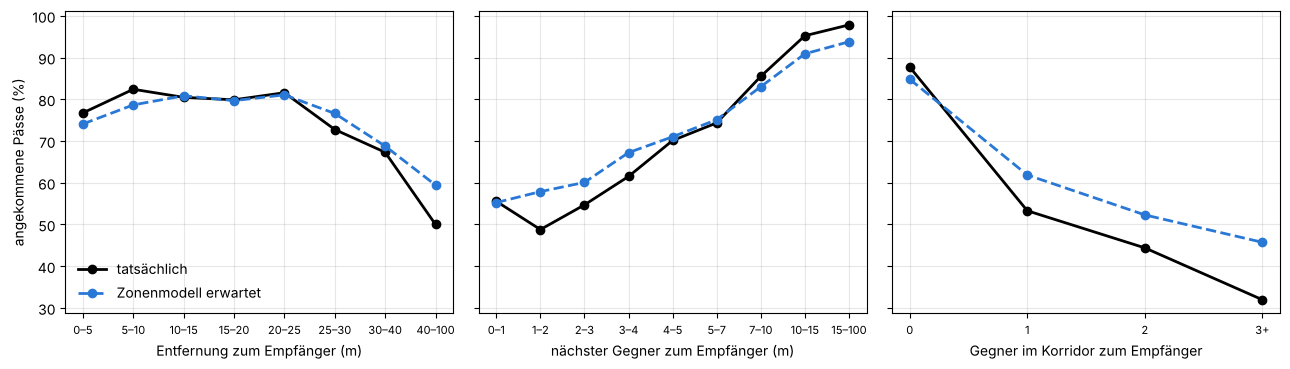

In [5]:
klassen = {
    "empf_distanz": ("Entfernung zum Empfänger (m)", [0, 5, 10, 15, 20, 25, 30, 40, 100]),
    "empf_gegner_abstand": ("nächster Gegner zum Empfänger (m)", [0, 1, 2, 3, 4, 5, 7, 10, 15, 100]),
    "korridor_gegner": ("Gegner im Korridor zum Empfänger", [-0.5, 0.5, 1.5, 2.5, 100]),
}
fig, achsen = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (spalte, (titel, grenzen)) in zip(achsen, klassen.items()):
    t = (pd.DataFrame({"klasse": pd.cut(daten[spalte], grenzen), "erfolg": y, "zonen": p_zonen})
         .groupby("klasse", observed=True).agg(tatsaechlich=("erfolg", "mean"), zonenmodell=("zonen", "mean")))
    beschriftung = ["0", "1", "2", "3+"] if spalte == "korridor_gegner" else [f"{i.left:g}–{i.right:g}" for i in t.index]
    ax.plot(beschriftung, t["tatsaechlich"] * 100, "o-", color="black", lw=2, label="tatsächlich")
    ax.plot(beschriftung, t["zonenmodell"] * 100, "o--", color=FARBEN["Zonenmodell"], lw=2, label="Zonenmodell erwartet")
    ax.set_xlabel(titel)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3)
achsen[0].set_ylabel("angekommene Pässe (%)")
achsen[0].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

- **Korridor:** das stärkste Signal. Ohne Gegner im Weg kommen 88 % der Pässe an, mit einem Gegner 53 %, ab drei Gegnern 32 %. Das Zonenmodell erwartet 85 %, 62 % und 46 %, sieht den Unterschied also nur zum Teil.
- **Freiraum des Empfängers:** Steht der nächste Gegner höchstens 3 m vom Empfänger entfernt, kommen 49–56 % an, ab 10 m 95–98 %. Das Zonenmodell erwartet bei 1–3 m zu viel und ab 10 m zu wenig.
- **Entfernung:** Bis 25 m kaum ein Unterschied, danach sinkt die Quote (über 40 m: 50 %). Den größten Teil davon kennt das Zonenmodell schon über Ort, Richtung und hohe Bälle.

## 4. Modell

Logistische Regression mit 21 Merkmalen. Die Tracking-Merkmale haben verschiedene Einheiten (Meter, Anzahl), deshalb werden alle Merkmale vor der Regression standardisiert; so wirkt die leichte Regularisierung von scikit-learn auf alle gleich.

Bewertung wie beim Zonenmodell: **Leave-one-match-out**. Trainiert und vorhergesagt wird nur auf Pässen mit sicher gefundenem Abspielmoment (Stufe 1 und 2); Pässe der Stufe 3 bekommen die Vorhersage des Zonenmodells. Die Tabelle zeigt, warum: Auf Stufe 3 bringt das Tracking nichts, weil Positionen und Richtung von einem ungenauen Zeitpunkt stammen.

In [6]:
def standardisiert():
    return make_pipeline(StandardScaler(), neues_modell())


X_empf = modell_merkmale(daten)
p_empf = leave_one_match_out_mit_rueckfall(X_empf, y, spiele, sicher, p_zonen, standardisiert)
p_alle_stufen = leave_one_match_out(X_empf, y, spiele, standardisiert)

pd.DataFrame({
    name: {**{f"Stufe {s} (n = {(stufe == s).sum()})": log_loss(y[stufe == s], p[stufe == s]) for s in [1, 2, 3]},
           "alle": log_loss(y, p)}
    for name, p in [("Zonenmodell", p_zonen), ("Empfänger-Modell, auf allen Stufen", p_alle_stufen),
                    ("Empfänger-Modell, Stufe 3 = Zonenmodell (gewählt)", p_empf)]
}).T.round(4)

,Stufe 1 (n = 5027),Stufe 2 (n = 284),Stufe 3 (n = 344),alle
Zonenmodell,0.3568,0.6544,0.4350,0.3765
"Empfänger-Modell, auf allen Stufen",0.3417,0.6544,0.4356,0.3631
"Empfänger-Modell, Stufe 3 = Zonenmodell (gewählt)",0.3418,0.6552,0.4350,0.3632


## 5. Vergleich mit dem Zonenmodell

Differenz im Log-Loss mit 95-%-Intervall aus dem Spiele-Bootstrap: 2.000-mal 7 Spiele mit Zurücklegen ziehen. Liegt das Intervall ganz unter 0, ist das Empfänger-Modell verlässlich besser.

Danach getrennt nach **klarer und unklarer Wahl des Empfängers**. Baut das Modell wirklich auf dem Empfänger auf, sollte es dort gewinnen, wo der Empfänger klar bestimmt ist. (Pässe mit klarer Wahl sind auch leichter; verglichen werden deshalb immer beide Modelle innerhalb derselben Gruppe.)

In [7]:
def vergleich(maske):
    d, unten, oben = logloss_differenz(y[maske], p_empf[maske], p_zonen[maske], spiele[maske])
    return {"Pässe": int(maske.sum()),
            "Log-Loss Zonenmodell": round(log_loss(y[maske], p_zonen[maske]), 4),
            "Log-Loss Empfänger-Modell": round(log_loss(y[maske], p_empf[maske]), 4),
            "AUC Zonenmodell": round(roc_auc_score(y[maske], p_zonen[maske]), 3),
            "AUC Empfänger-Modell": round(roc_auc_score(y[maske], p_empf[maske]), 3),
            "Δ Log-Loss [95 %]": f"{d:+.4f} [{unten:+.4f}; {oben:+.4f}]"}


pd.DataFrame({"alle Pässe": vergleich(np.ones(len(y), bool)), "klare Wahl": vergleich(klar),
              "unklare Wahl": vergleich(~klar)}).T

,Pässe,Log-Loss Zonenmodell,Log-Loss Empfänger-Modell,AUC Zonenmodell,AUC Empfänger-Modell,Δ Log-Loss [95 %]
alle Pässe,5655,0.3765,0.3632,0.847,0.865,-0.0133 [-0.0211; -0.0056]
klare Wahl,3824,0.3223,0.3016,0.848,0.877,-0.0208 [-0.0303; -0.0115]
unklare Wahl,1831,0.4897,0.4919,0.812,0.813,+0.0022 [-0.0102; +0.0125]


- **Insgesamt** ist das Empfänger-Modell klar besser als das Zonenmodell: Log-Loss 0,3765 → 0,3632 (−3,5 %, Intervall ganz unter 0), AUC 0,847 → 0,865.
- **Bei klarer Wahl** (68 % der Pässe) ist der Gewinn größer (−0,021).
- **Bei unklarer Wahl** gewinnt es nichts (Intervall schließt 0 ein). Ist der Empfänger falsch geschätzt, beschreiben Entfernung, Freiraum und Korridor einen anderen Pass als den gespielten.

Die Empfänger-Merkmale tragen also, sobald die Schätzung stimmt. Eine bessere Empfänger-Schätzung sollte den Gewinn auf mehr Pässe ausdehnen.

## 6. Was hat das Modell gelernt?

Logistische Regression auf allen Pässen der Stufe 1 und 2 mit `statsmodels`, **ohne** Standardisierung, damit man die Tracking-Merkmale in ihren Einheiten lesen kann.

In [8]:
logit = sm.Logit(y[sicher], sm.add_constant(X_empf[sicher])).fit(disp=False)
pd.DataFrame({"Koeffizient": logit.params, "KI 2,5 %": logit.conf_int()[0], "KI 97,5 %": logit.conf_int()[1],
              "Odds-Ratio": np.exp(logit.params), "p-Wert": logit.pvalues}).round(3)

,Koeffizient,"KI 2,5 %","KI 97,5 %",Odds-Ratio,p-Wert
const,1.817,1.426,2.209,6.156,0.000
flanke,-0.237,-0.735,0.261,0.789,0.350
freistoss,0.107,-0.407,0.622,1.113,0.682
abstoss,-0.477,-1.178,0.224,0.621,0.182
hoch,-1.510,-1.697,-1.323,0.221,0.000
tiefe,-0.746,-0.991,-0.501,0.474,0.000
breite,0.412,0.074,0.749,1.509,0.017
zone_erstes_zentrum,0.138,-0.263,0.539,1.148,0.501
zone_erstes_fluegel,-0.263,-0.674,0.148,0.769,0.209
zone_mittleres_fluegel,-0.301,-0.552,-0.049,0.740,0.019


**Tracking-Merkmale** (alle Intervalle klar von 0 verschieden):
- `druck_abstand`: je Meter Abstand des nächsten Gegners zum Passgeber (bis 15 m) ca. +10 % auf die Chance.
- `empf_distanz`: je Meter Entfernung zum Empfänger ca. −4 %; 10 m weiter heißt ca. −32 %.
- `empf_gegner_abstand`: je Meter Freiraum des Empfängers (bis 20 m) ca. +13 %.
- `korridor_gegner`: je Gegner im Weg zum Empfänger ca. −23 %.

Die Zonen-Gewichte ändern sich gegenüber Notebook 02, weil die Tracking-Merkmale einen Teil dessen erklären, was vorher Ort und Richtung erklären mussten. Beispiel: `zone_erstes_zentrum` +1,21 → +0,14 (in der eigenen Hälfte stehen weniger Gegner im Weg und die Empfänger freier), `hoch` −1,91 → −1,51.

## 7. Kalibrierung: gesamt und je Rolle

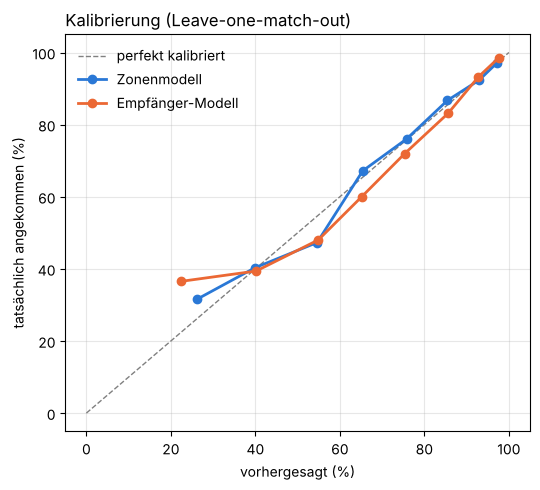

Steilpässe (DFL throughBall, n = 307): tatsächlich 30%, Zonenmodell 45%, Empfänger-Modell 47%


,Zonenmodell: Pässe,Zonenmodell: tatsächlich − erwartet (Pp.),Empfänger-Modell: Pässe,Empfänger-Modell: tatsächlich − erwartet (Pp.)
Vorhersage-Klasse,,,,
"(0.0, 0.3]",171,5.4,312,14.1
"(0.3, 0.5]",851,0.4,632,-0.8
"(0.5, 0.6]",296,-7.3,302,-6.9
"(0.6, 0.7]",195,1.8,295,-5.2
"(0.7, 0.8]",476,0.2,489,-3.4
"(0.8, 0.9]",1039,1.3,811,-2.5
"(0.9, 0.95]",851,-0.6,798,0.4
"(0.95, 1.0]",1776,-0.1,2016,0.9


In [9]:
klassen_p = [0, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 100], [0, 100], "--", color="grey", lw=1, label="perfekt kalibriert")
tabelle = {}
for name, p in [("Zonenmodell", p_zonen), ("Empfänger-Modell", p_empf)]:
    g = pd.DataFrame({"p": p, "y": y}).groupby(pd.cut(p, klassen_p), observed=True)
    ax.plot(g["p"].mean() * 100, g["y"].mean() * 100, "o-", color=FARBEN[name], lw=2, label=name)
    tabelle[f"{name}: Pässe"] = g.size()
    tabelle[f"{name}: tatsächlich − erwartet (Pp.)"] = ((g["y"].mean() - g["p"].mean()) * 100).round(1)
ax.set_xlabel("vorhergesagt (%)"); ax.set_ylabel("tatsächlich angekommen (%)")
ax.grid(alpha=0.3); ax.legend(frameon=False)
ax.set_title("Kalibrierung (Leave-one-match-out)", loc="left")
plt.tight_layout(); plt.show()
print(f"Steilpässe (DFL throughBall, n = {steil.sum()}): tatsächlich {y[steil].mean():.0%}, "
      f"Zonenmodell {p_zonen[steil].mean():.0%}, Empfänger-Modell {p_empf[steil].mean():.0%}")
pd.DataFrame(tabelle).rename_axis("Vorhersage-Klasse")

In [10]:
# Je Rolle des Passgebers: tatsächlich − erwartet in Prozentpunkten (negativ = das Modell überschätzt die Gruppe)
rollen = mit_rollen(daten[["match_id", "player_id", "erfolg"]].assign(zonen=p_zonen, empfaenger=p_empf), MATCH_IDS)
je_rolle = rollen.groupby("rolle")[["erfolg", "zonen", "empfaenger"]].mean().loc[ROLLEN]
pd.DataFrame({"Pässe": rollen["rolle"].value_counts()[ROLLEN],
              "Zonenmodell": (je_rolle["erfolg"] - je_rolle["zonen"]) * 100,
              "Empfänger-Modell": (je_rolle["erfolg"] - je_rolle["empfaenger"]) * 100}).round(1)

,Pässe,Zonenmodell,Empfänger-Modell
rolle,,,
Torwart,633,0.8,-2.4
Innenverteidiger,1509,3.2,2.3
Außenverteidiger,1033,-0.4,-0.1
Zentrales Mittelfeld,1138,0.4,0.7
Flügel,629,-2.2,-1.2
Zehner/Sturm,713,-5.4,-4.3


- **Gesamt:** Das Empfänger-Modell traut sich mehr extreme Vorhersagen zu (312 Pässe unter 30 % statt 171). Dort ist es zu pessimistisch (14 Prozentpunkte mehr angekommen als erwartet), zwischen 60 und 90 % leicht zu optimistisch (2–5 Prozentpunkte). Ursache: Die logistische Regression zählt Risiken zusammen (hoher Ball, Gegner im Weg, Empfänger eng gedeckt); in Wirklichkeit gibt es eine Untergrenze, weil zum Beispiel hohe Bälle oft im Kopfballduell entschieden werden.
- **Steilpässe** werden weiter überschätzt (47 % erwartet, 30 % tatsächlich). Hier liegt die Empfänger-Regel am häufigsten daneben.
- **Je Rolle:** Die Verzerrung aus Notebook 03 wird etwas kleiner, bleibt aber: Zehner/Sturm −5,4 → −4,3, Innenverteidiger +3,2 → +2,3. Spieler deshalb auch mit diesem Modell nur innerhalb ihrer Rolle vergleichen.

## 8. Bewusst nicht im Modell: Winkel zum Empfänger

Naheliegend wäre ein weiteres Merkmal: der Winkel zwischen Passrichtung und (vorausgerechnetem) Empfänger, also wie weit der Ball am Empfänger vorbeigeht.

In [11]:
p_winkel = leave_one_match_out_mit_rueckfall(modell_merkmale(daten, mit_winkel=True), y, spiele, sicher,
                                             p_zonen, standardisiert)
d, unten, oben = logloss_differenz(y, p_winkel, p_empf, spiele)
print(f"Empfänger-Modell + Winkel: Log-Loss {log_loss(y, p_winkel):.4f}, "
      f"Differenz zum Empfänger-Modell {d:+.4f} [{unten:+.4f}; {oben:+.4f}]")
gross = (daten["empf_winkel"] > 20).to_numpy()
print(f"Empfänger richtig (angekommene Pässe): Winkel über 20° {treffer[angekommen & gross].mean():.0%}, "
      f"sonst {treffer[angekommen & ~gross].mean():.0%}")

Empfänger-Modell + Winkel: Log-Loss 0.3527, Differenz zum Empfänger-Modell -0.0105 [-0.0146; -0.0058]
Empfänger richtig (angekommene Pässe): Winkel über 20° 68%, sonst 83%


Mit dem Winkel wäre das Modell noch einmal besser. Trotzdem bleibt er draußen, denn er mischt drei Dinge:
1. bewusst vorgelegte Bälle, die weiter führen als die 1-s-Vorausrechnung,
2. ungenau gespielte Bälle, also schon die Ausführung,
3. Fehler der Empfänger-Schätzung: Bei großen Winkeln ist der Empfänger deutlich öfter falsch geschätzt.

Für die Spielerauswertung wäre Punkt 2 problematisch: Ein ungenau gespielter Pass würde dann schon als schwer gelten und den Spieler kaum etwas kosten. Mit einer besseren Empfänger-Schätzung lohnt sich ein neuer Test.

## 9. Was ändert sich für die Spielerauswertung?

Pässe über Erwartung pro 100 Pässe (wie Notebook 03) mit beiden Modellen, für Spieler mit mindestens 50 Pässen.

In [12]:
basis = daten[["player", "team", "erfolg"]]
zonen_bilanz = bilanz(basis.assign(xpass=p_zonen), ["player", "team"])
empf_bilanz = bilanz(basis.assign(xpass=p_empf), ["player", "team"])
spieler = pd.DataFrame({"Pässe": zonen_bilanz["paesse"], "Zonenmodell": zonen_bilanz["pue_100"],
                        "Empfänger-Modell": empf_bilanz["pue_100"], "Zufall (±1 SD)": empf_bilanz["zufall_100"]})
spieler = spieler[spieler["Pässe"] >= 50]
spieler["Änderung"] = spieler["Empfänger-Modell"] - spieler["Zonenmodell"]
print(f"{len(spieler)} Spieler; Rangkorrelation (Spearman) zwischen den Modellen: "
      f"{spieler['Zonenmodell'].corr(spieler['Empfänger-Modell'], method='spearman'):.2f}; "
      f"Änderung je Spieler: Standardabweichung {spieler['Änderung'].std():.1f} pro 100 Pässe")
spieler.sort_values("Empfänger-Modell", ascending=False).round(1)

29 Spieler; Rangkorrelation (Spearman) zwischen den Modellen: 0.91; Änderung je Spieler: Standardabweichung 1.5 pro 100 Pässe


,,Pässe,Zonenmodell,Empfänger-Modell,Zufall (±1 SD),Änderung
player,team,,,,,
Benjamin Pavard,FC Bayern München,55,6.0,7.2,4.5,1.2
Timo Hübers,1. FC Köln,59,7.5,7.1,3.7,-0.4
M. Sobottka,Fortuna Düsseldorf,175,8.1,6.8,2.1,-1.3
Eric Smith,FC St. Pauli,62,3.7,4.7,3.3,1.0
Dayot Upamecano,FC Bayern München,76,4.1,3.8,3.3,-0.3
C. Klarer,Fortuna Düsseldorf,200,4.5,3.7,1.9,-0.8
Jordy de Wijs,Fortuna Düsseldorf,56,5.4,3.3,4.0,-2.1
Tim Oberdorf,Fortuna Düsseldorf,261,6.3,3.2,1.7,-3.1
B. Fazliji,FC St. Pauli,57,2.6,3.1,3.8,0.5


Die Rangfolge bleibt nah am Zonenmodell (Rangkorrelation 0,91). Einzelne Spieler verschieben sich im Mittel um ±1,5 Pässe pro 100, also weniger als der Zufall (±2–5). Sobottka bleibt vorn (+8,1 → +6,8). Deutlich sinken zum Beispiel Kastenmeier (Torwart, −3,5) und Oberdorf (Innenverteidiger, −3,1): Ihre Empfänger standen im Schnitt deutlich freier (12 bzw. 11 m bis zum nächsten Gegner, Durchschnitt aller Pässe 8,5 m), und sie selbst standen kaum unter Druck. Ihre Pässe waren also leichter, als das Zonenmodell annahm. Die Aussagen aus Notebook 03 zur Belastbarkeit gelten weiter.

## 10. Vorhersagen speichern

In [13]:
spalten = ["match_id", "liga", "event_id", "period", "t", "team_id", "team", "player_id", "player", "standard", "flanke",
           "hoehe", "x", "y", "erfolg", "sync_stufe", "richtung", "druck_abstand", "empf", "empf_distanz",
           "empf_gegner_abstand", "korridor_gegner", "empf_winkel", "eindeutigkeit"]
ausgabe = daten[spalten].assign(xpass_zonen=p_zonen, xpass_empfaenger=p_empf,
                                empf_richtig=np.where(angekommen, treffer.astype(float), np.nan))
ausgabe.to_csv(DATA / "vorhersagen_empfaenger.csv", index=False)
print(f"gespeichert: data/vorhersagen_empfaenger.csv ({len(ausgabe)} Pässe)")

gespeichert: data/vorhersagen_empfaenger.csv (5655 Pässe)


## Fazit

| | Zonenmodell (Notebook 02) | Empfänger-Modell |
|---|---|---|
| Daten | Events | Events + Tracking im Abspielmoment |
| Merkmale | 17 | 17 + 4 (Druck, Entfernung zum Empfänger, Freiraum des Empfängers, Gegner im Korridor) |
| Log-Loss (alle Pässe) | 0,3765 | **0,3632** (−3,5 %, Intervall unter 0) |
| AUC | 0,847 | 0,865 |
| Log-Loss bei klarer / unklarer Wahl des Empfängers | 0,322 / 0,490 | 0,302 / 0,492 |
| Abweichung Zehner/Sturm | −5,4 | −4,3 |

- **Was die Erweiterung bringt:** die Gegnerpositionen, die dem Zonenmodell fehlen. Jedes Tracking-Merkmal ist fußballerisch plausibel und klar wirksam; am stärksten die Gegner im Weg und der Freiraum des Empfängers.
- **Wo der Engpass liegt:** in der Schätzung des Empfängers. Ist er klar bestimmt, gewinnt das Modell deutlich; ist er unklar, gewinnt es nichts.

**Grenzen:**
- Empfänger-Regel: 82 % richtig bei angekommenen Pässen, 53 % bei hohen Bällen, 23 % bei Steilpässen; bei Fehlpässen nicht prüfbar. Die Parameter (1 s Vorausrechnung, 0,5 Punkte je Meter) wurden auf denselben 7 Spielen gewählt.
- Rollen-Verzerrung und Überschätzung der Steilpässe bleiben; bei sehr riskanten Pässen ist das Modell zu pessimistisch.
- 6 % der Pässe (Abspielmoment nur grob gefunden) bekommen weiter die Vorhersage des Zonenmodells.

**Nächster Schritt:** die Empfänger-Schätzung verbessern, z. B. ein an angekommenen Pässen gelerntes Empfänger-Modell statt der festen Regel, oder Wahrscheinlichkeiten über mehrere mögliche Empfänger statt einer harten Wahl.